# **INM434 Natural Language Processing Coursework**

**Title:** Domain Adaptation in NLP: Evaluating Transformer Performance on Financial Sentiment Analysis  
**Author:** Mario Andres Melo Ceron  
**Programme:** MSc Data Science, City St George's, University of London


**Note on Text Preprocessing**

Throughout this notebook, all TF-IDF with Logistic Regression experiments use preprocessed text, including regex cleaning, lowercasing, negation handling, stopword removal, and lemmatisation. All transformer-based models (BERT, FinBERT) use raw, unprocessed text as input. Preprocessing is not applied to transformer inputs, in line with standard practice, to avoid disrupting subword tokenisation and contextual representations learned during pre-training. Preprocessing is used for TF-IDF features to reduce surface redundancy and vocabulary size.

**Attribution**

Methods and libraries used in this notebook are attributed in code comments at the point of use. Full citations in ACL format are provided in the accompanying report.


**Appendix: Generative AI Declaration**

**Tool used:** ChatGPT

**Purpose and scope of use:**
- Code debugging
- Improving code readability and commenting clarity
- Reviewing structure and formatting of markdown sections

**AI was NOT used for:**
- Algorithm design
- Analysis, interpretation, or results discussion
- Writing of analytical or concluding text
- Any form of experimental decision-making

In [1]:
# Purpose: Install all required external libraries for the NLP pipeline.
# datasets: For loading and processing the Financial PhraseBank dataset.
# transformers: For pre-trained language models, tokenisation, and the Trainer API.
# scikit-learn: For traditional machine learning baselines and evaluation metrics.
# seaborn and matplotlib: For generating graphical visualisations such as confusion matrices.
# nltk: For natural language preprocessing, including lemmatisation and stopword removal.
# accelerate: To optimise HuggingFace model training performance on the GPU.

!pip install -q "datasets<4.0.0" "transformers>=4.46" scikit-learn seaborn matplotlib nltk accelerate

## Google Drive Mount

All experimental outputs, including model checkpoints, evaluation plots, CSV files, and submission archives, are saved to Google Drive for persistence across disconnections. Mounting Google Drive ensures that all computationally expensive artefacts remain accessible throughout multiple training sessions.

In [2]:
# Purpose: Mount Google Drive and establish persistent output directories so that
# training checkpoints and submission artefacts are not lost upon runtime reset.

from google.colab import drive
import os

drive.mount('/content/drive')

# Define the single root directory for all outputs.
# All cells writing files reference BASE_DIR
BASE_DIR = '/content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs'

os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)
os.makedirs(f'{BASE_DIR}/bert_output', exist_ok=True)
os.makedirs(f'{BASE_DIR}/finberttone_output', exist_ok=True)

print('Google Drive mounted successfully.')
print(f'Persistent working directory established at: {BASE_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.
Persistent working directory established at: /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs


In [3]:
# Remove stale artefacts from previous runs before training begins,
# ensuring the submission package contains only current-run results.

import shutil

submission_path = f'{BASE_DIR}/submission'
if os.path.isdir(submission_path):
    shutil.rmtree(submission_path)
os.makedirs(submission_path, exist_ok=True)

zip_path = f'{BASE_DIR}/submission.zip'
if os.path.isfile(zip_path):
    os.remove(zip_path)

# Clean output directories to avoid checkpoint accumulation. Recreate empty.
for _out in [f'{BASE_DIR}/bert_output', f'{BASE_DIR}/finberttone_output']:
    if os.path.isdir(_out):
        shutil.rmtree(_out)
    os.makedirs(_out, exist_ok=True)

print(f'Cleaned submission staging: {submission_path}')
print('Cleaned transformer output directories')
print(f'Removed stale zip if present: {zip_path}')

Cleaned submission staging: /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission
Cleaned transformer output directories
Removed stale zip if present: /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission.zip


## Imports, Seeds, and Environment Setup

All imports are consolidated in a single cell to make dependency management explicit. Random seeds are set across Python, NumPy, PyTorch, CUDA, and HuggingFace to ensure reproducibility of results. NLTK resources are downloaded here to prevent errors during text preprocessing.


In [4]:
# Purpose: Import all required libraries, fix all random seeds, download NLTK
# resources, and confirm GPU availability.

import sys
import gc
import re
import csv
import random
import warnings

import numpy as np
import pandas as pd
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    f1_score
)

import torch
import torch.nn as nn

import transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed as hf_set_seed
)
from datasets import load_dataset

warnings.filterwarnings('ignore')

# Global seed used consistently across all splits, initialisations, and data loaders.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
hf_set_seed(SEED)

# Deterministic cuDNN behaviour ensures that convolution algorithm selection
# does not vary across runs, which would otherwise break reproducibility
# even when all seeds are fixed.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# All five NLTK resources are downloaded here. The preprocessing
# function never raises a LookupError at runtime. punkt_tab is required
# by newer NLTK versions on current Colab images.
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('WARNING: No GPU detected. Transformer training will be slow.')

print(f'Python:       {sys.version}')
print(f'PyTorch:      {torch.__version__}')
print(f'Transformers: {transformers.__version__}')

Device: cuda
GPU: Tesla T4
GPU memory: 15.6 GB
Python:       3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch:      2.10.0+cu128
Transformers: 5.0.0


In [5]:
# Purpose: Authenticate with the HuggingFace Hub by securely retrieving the token from the Colab environment.

from huggingface_hub import login
from google.colab import userdata

try:
    hf_token = userdata.get('HF_TOKEN')
    login(token=hf_token)
    print('HuggingFace login successful.')
except userdata.SecretNotFoundError:
    print('WARNING: HF_TOKEN not found in Colab Secrets. Please add it to the sidebar.')

HuggingFace login successful.


## Dataset Loading

The Financial PhraseBank dataset (Malo et al., 2014) is loaded via the HuggingFace datasets library. The sentences_allagree configuration is used because unanimous annotator agreement minimises label noise, making it the most reliable subset for evaluating model performance.

In [6]:
# Purpose: Load the Financial PhraseBank dataset using the Parquet-based loader
# from the takala/financial_phrasebank repository on the HuggingFace Hub.
# The script-based loader is no longer supported in datasets >= 4.0, the
# Parquet path is used instead.
# Dataset attribution: Malo et al. (2014).

raw_dataset = load_dataset(
    'takala/financial_phrasebank',
    'sentences_allagree',
    trust_remote_code=True
)

print('Dataset loaded.')
print(f'Available splits: {list(raw_dataset.keys())}')

df = raw_dataset['train'].to_pandas()
print(f'Total sentences: {len(df)}')
print(df.head())

# The canonical label names are read directly from the dataset features
# rather than hardcoded, confusion matrix axes are never silently
# misaligned if the integer-to-label mapping differs from expectation.
LABEL_NAMES = raw_dataset['train'].features['label'].names
print(f'Label names: {LABEL_NAMES}')

Dataset loaded.
Available splits: ['train']
Total sentences: 2264
                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  For the last quarter of 2010 , Componenta 's n...      2
2  In the third quarter of 2010 , net sales incre...      2
3  Operating profit rose to EUR 13.1 mn from EUR ...      2
4  Operating profit totalled EUR 21.1 mn , up fro...      2
Label names: ['negative', 'neutral', 'positive']


## Exploratory Data Analysis (EDA)

Class distribution and BERT-tokenised sentence length statistics are reported here.  
The max_length parameter for transformer tokenisation is determined empirically from the actual token length distribution rather than assumed, ensuring at least 95% of sentences are covered without truncation.

Class distribution:
  negative     (id=0):   303  (13.4%)
  neutral      (id=1):  1391  (61.4%)
  positive     (id=2):   570  (25.2%)


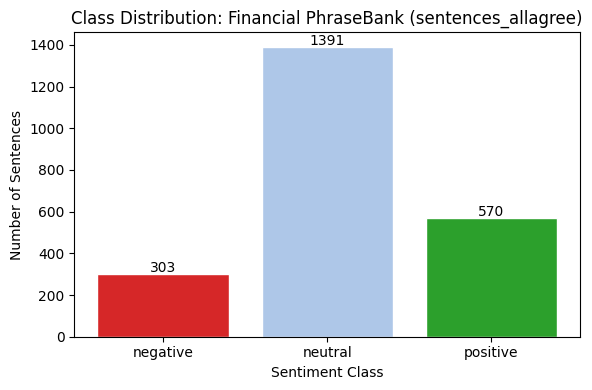


Token length statistics:
  Mean:            30.2
  Median:          28.0
  Max:             150
  95th percentile: 58.0

Coverage at max_length=64: 98.1%
max_length set to 64 (coverage 98.1%, meets the 95% threshold).
Final MAX_LENGTH: 64 (coverage 98.1%)


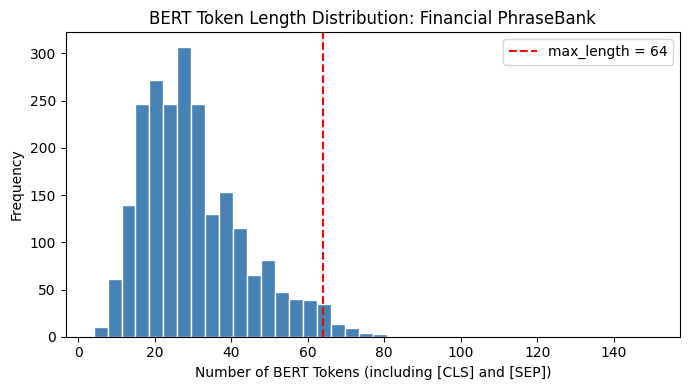

In [7]:
# Purpose: Perform exploratory data analysis to evaluate class distributions
# and compute the optimal sequence length for transformer tokenisation
# based on the actual BERT token length distribution.

print('Class distribution:')
for label_id, label_name in enumerate(LABEL_NAMES):
    count = int((df['label'] == label_id).sum())
    pct = count / len(df) * 100
    print(f'  {label_name:12s} (id={label_id}): {count:5d}  ({pct:.1f}%)')

fig, ax = plt.subplots(figsize=(6, 4))
counts = [int((df['label'] == i).sum()) for i in range(len(LABEL_NAMES))]
colours = ['#d62728', '#aec7e8', '#2ca02c']
bars = ax.bar(LABEL_NAMES, counts, color=colours, edgecolor='white')
ax.set_title('Class Distribution: Financial PhraseBank (sentences_allagree)')
ax.set_xlabel('Sentiment Class')
ax.set_ylabel('Number of Sentences')
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 8, str(c), ha='center', fontsize=10)
plt.tight_layout()
plt.savefig(f'{BASE_DIR}/submission/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

# Use the BERT tokenizer for token length analysis.
eda_tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

token_lengths = np.array([
    len(eda_tokenizer.encode(text, add_special_tokens=True))
    for text in df['sentence']
])

print(f'\nToken length statistics:')
print(f'  Mean:            {token_lengths.mean():.1f}')
print(f'  Median:          {np.median(token_lengths):.1f}')
print(f'  Max:             {token_lengths.max()}')
print(f'  95th percentile: {np.percentile(token_lengths, 95):.1f}')

coverage_64 = float((token_lengths <= 64).sum()) / len(token_lengths) * 100
print(f'\nCoverage at max_length=64: {coverage_64:.1f}%')

# Select MAX_LENGTH for at least 95% coverage.
if coverage_64 >= 95.0:
    MAX_LENGTH = 64
    final_coverage = coverage_64
    print(f'max_length set to 64 (coverage {coverage_64:.1f}%, meets the 95% threshold).')
else:
    MAX_LENGTH = 128
    final_coverage = float((token_lengths <= 128).sum()) / len(token_lengths) * 100
    print(f'max_length increased to 128 (coverage at 64 was {coverage_64:.1f}%, below 95%).')
    print(f'Coverage at max_length=128: {final_coverage:.1f}%')

assert final_coverage >= 95.0, (
    f'Chosen MAX_LENGTH={MAX_LENGTH} only covers {final_coverage:.1f}% of '
    f'sentences, below the 95% threshold stated in the methodology.'
)

print(f'Final MAX_LENGTH: {MAX_LENGTH} (coverage {final_coverage:.1f}%)')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(token_lengths, bins=40, color='steelblue', edgecolor='white')
ax.axvline(MAX_LENGTH, color='red', linestyle='--', label=f'max_length = {MAX_LENGTH}')
ax.set_title('BERT Token Length Distribution: Financial PhraseBank')
ax.set_xlabel('Number of BERT Tokens (including [CLS] and [SEP])')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.savefig(f'{BASE_DIR}/submission/token_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

del eda_tokenizer
_ = gc.collect()

## Stratified Data Splitting

The dataset is divided into train (80%), validation (10%), and test (10%) using two sequential stratified splits with a fixed random seed. Stratification preserves class proportions across all three partitions. The test set is held out entirely until final evaluation; the validation set is used only for early stopping and checkpoint selection during transformer training.

In [8]:
# Purpose: Split the dataset into train, validation, and test sets using
# stratified sampling on integer indices.
# Materialise text and label lists from those indices.
# Splitting on indices makes disjointness checks unambiguous and avoids
# false positives from Python string interning.

texts  = df['sentence'].tolist()
labels = df['label'].tolist()

# Work with integer indices for unambiguous disjointness checks.
indices = np.arange(len(texts))

# First split: 80% train indices, 20% temp indices.
# Stratify on labels to keep class proportions.
idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

# Second split: split 20% temp into validation and test (10% each).
# Stratify on temp labels.
labels_temp_for_split = [labels[i] for i in idx_temp]
idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=labels_temp_for_split
)

# Disjointness checks on index sets.
train_set = set(idx_train.tolist())
val_set   = set(idx_val.tolist())
test_set  = set(idx_test.tolist())

assert len(train_set) + len(val_set) + len(test_set) == len(texts), \
    'Split sizes do not sum to the original dataset size.'
assert train_set.isdisjoint(val_set),  'Train and validation index sets overlap.'
assert train_set.isdisjoint(test_set), 'Train and test index sets overlap.'
assert val_set.isdisjoint(test_set),   'Validation and test index sets overlap.'

# Materialise the splits from indices.
texts_train  = [texts[i]  for i in idx_train]
texts_val    = [texts[i]  for i in idx_val]
texts_test   = [texts[i]  for i in idx_test]
labels_train = [labels[i] for i in idx_train]
labels_val   = [labels[i] for i in idx_val]
labels_test  = [labels[i] for i in idx_test]

print(f'Train size:      {len(texts_train)}')
print(f'Validation size: {len(texts_val)}')
print(f'Test size:       {len(texts_test)}')
print('\nClass proportions per split:')
for split_name, split_labels in [
    ('Train',      labels_train),
    ('Validation', labels_val),
    ('Test',       labels_test)
]:
    split_arr = np.array(split_labels)
    proportions = [f'{LABEL_NAMES[i]}: {(split_arr == i).mean():.3f}'
                   for i in range(len(LABEL_NAMES))]
    print(f'  {split_name:12s}: {", ".join(proportions)}')

Train size:      1811
Validation size: 226
Test size:       227

Class proportions per split:
  Train       : negative: 0.134, neutral: 0.615, positive: 0.252
  Validation  : negative: 0.133, neutral: 0.615, positive: 0.252
  Test        : negative: 0.137, neutral: 0.612, positive: 0.251


### Text Preprocessing Pipeline (TF-IDF Only)

This preprocessing function is applied exclusively to the TF-IDF input. It is never applied to transformer inputs.

The order of operations is fixed as follows:

1. **Regex cleaning:** expands "n't" contractions to "not", removes non-alphabetic characters, and normalises whitespace  
2. **Lowercasing**  
3. **Negation handling:** prefixes `NOT_` to the token immediately following a negation cue  
4. **Stopword removal**  
5. **Lemmatisation**

Negation handling must precede stopword removal. If stopwords are removed first, negation cues such as "not", "no", and "never" are stripped before they can modify the following token, which would cause sentiment-reversing negations to be silently lost from the feature representation.

In [9]:
# Construct a TF-IDF-specific text preprocessing pipeline.
# Includes explicit negation handling and lemmatisation.
# Ensures stopword and negation ordering does not lose sentiment context.
# Applied at TF-IDF fit/transform time via FunctionTransformer.

STOP_WORDS = set(stopwords.words('english'))
NEGATION_CUES = {'not', 'no', 'never', 'neither', 'nor', 'nobody', 'nothing',
                 'nowhere', 'hardly', 'scarcely', 'barely', "n't"}
STOP_WORDS -= NEGATION_CUES

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Step 1: Regex cleaning.
    text = re.sub(r"n't\b", " not", text, flags=re.IGNORECASE)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    # Step 2: Lowercase.
    text = text.lower()
    # Step 3: Negation handling.
    tokens = text.split()
    negated_tokens = []
    negate_next = False
    for token in tokens:
        if token in NEGATION_CUES:
            negate_next = True
            continue
        if negate_next:
            negated_tokens.append('NOT_' + token)
            negate_next = False
        else:
            negated_tokens.append(token)
    tokens = negated_tokens
    # Step 4: Stopword removal.
    tokens = [t for t in tokens if t not in STOP_WORDS]
    # Step 5: Lemmatisation.
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

# Sanity check on a single training example.
print('Preprocessing function defined.')
print(f'Sample raw text:     {texts_train[0]}')
print(f'Sample preprocessed: {preprocess_text(texts_train[0])}')

Preprocessing function defined.
Sample raw text:     Merrill Lynch analyst Campbell Morgan upgraded his recommendation on PaperlinX from `` neutral '' to `` buy '' in May .
Sample preprocessed: merrill lynch analyst campbell morgan upgraded recommendation paperlinx neutral buy may


## Evaluation Utilities

A shared helper function produces a consistent set of metrics and visualisations for every model. This function computes macro-averaged precision, recall, and F1, prints a per-class classification report, and renders a labelled confusion matrix heatmap. The confusion matrix label order is read from the dataset features so that axes are never silently misaligned.

In [10]:
# Purpose: Provide a unified evaluation function for all models.
# Reports both macro and weighted metrics. Both are needed because the dataset is class-imbalanced
# and to justify the primary metric choice. Saves a labelled confusion matrix.

def evaluate_model(model_name, y_true, y_pred, label_names):
    # Macro averages treat each class equally. Used as the primary metric for fairness.
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    # Weighted averages reflect support-weighted performance. Included for reporting the gap.
    precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )

    print(f'\nResults: {model_name}')
    print(f'  Macro F1:        {f1_macro:.4f}')
    print(f'  Macro Precision: {precision_macro:.4f}')
    print(f'  Macro Recall:    {recall_macro:.4f}')
    print(f'  Weighted F1:     {f1_w:.4f}')
    print('\nPer-class report:')
    print(classification_report(y_true, y_pred,
                                target_names=label_names,
                                zero_division=0))

    # Confusion matrix with fixed label order for correct annotation.
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(label_names))))
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_names,
                yticklabels=label_names,
                ax=ax)
    ax.set_title(f'Confusion Matrix: {model_name}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()

    # Save the confusion matrix image in the submission directory.
    safe_name = model_name.lower().replace(' ', '_').replace('/', '_')
    os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)
    plt.savefig(f'{BASE_DIR}/submission/cm_{safe_name}.png', dpi=150,
                bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return {
        'model_name': model_name,
        'f1':         f1_macro,
        'precision':  precision_macro,
        'recall':     recall_macro,
        'f1_weighted': f1_w,
    }

## Majority Class Baseline

The majority class baseline predicts the most frequent label in the training set. It establishes a lower bound for all other models and is excluded from model saving because it has no learnable parameters or serialisable object to persist.


Results: Majority Class Baseline
  Macro F1:        0.2532
  Macro Precision: 0.2041
  Macro Recall:    0.3333
  Weighted F1:     0.4651

Per-class report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        31
     neutral       0.61      1.00      0.76       139
    positive       0.00      0.00      0.00        57

    accuracy                           0.61       227
   macro avg       0.20      0.33      0.25       227
weighted avg       0.37      0.61      0.47       227



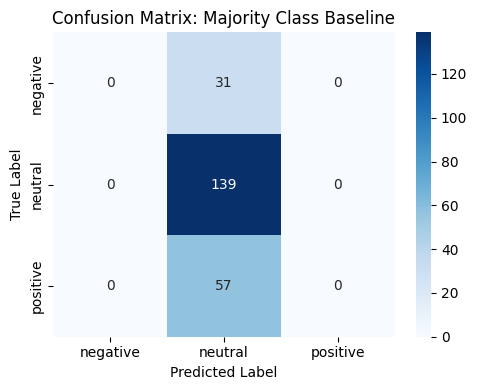

In [11]:
# Purpose: Implement the majority class (most frequent label) baseline
# for the TF-IDF pipeline using scikit-learn's DummyClassifier.

# Majority Class baseline implemented via scikit-learn DummyClassifier (Pedregosa et al., 2011).
# Pattern adapted from INM434 Lab 02.
#
# DummyClassifier with strategy='most_frequent' predicts the dominant class.
# This baseline reveals how much variance a trivial rule can explain and
# sets a floor that every other model must exceed to demonstrate learning.

dummy_clf = DummyClassifier(strategy='most_frequent', random_state=SEED)
dummy_clf.fit(texts_train, labels_train)

dummy_preds = dummy_clf.predict(texts_test)

majority_results = evaluate_model(
    'Majority Class Baseline',
    labels_test,
    dummy_preds,
    LABEL_NAMES
)

## TF-IDF with Logistic Regression Baseline

A TF-IDF vectoriser with bigrams is combined with logistic regression in a single sklearn Pipeline. The vectoriser is fitted exclusively on the training set; the validation and test sets use transform only, preventing any information from leaking into the feature vocabulary through test-set term frequencies.


Results: TF-IDF Logistic Regression
  Macro F1:        0.7948
  Macro Precision: 0.7978
  Macro Recall:    0.7945
  Weighted F1:     0.8386

Per-class report:
              precision    recall  f1-score   support

    negative       0.76      0.81      0.78        31
     neutral       0.90      0.93      0.91       139
    positive       0.74      0.65      0.69        57

    accuracy                           0.84       227
   macro avg       0.80      0.79      0.79       227
weighted avg       0.84      0.84      0.84       227



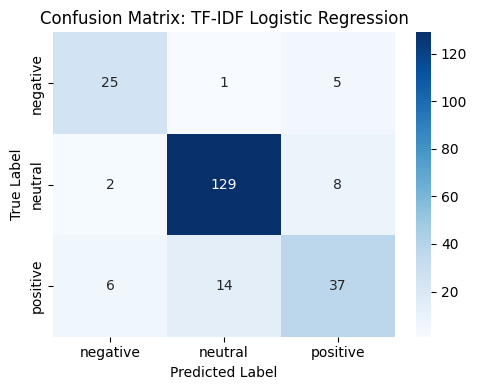

In [12]:
# Purpose: TF-IDF + Logistic Regression baseline as a fully self-contained scikit-learn Pipeline.
# Wrapping preprocess_text via FunctionTransformer ensures .predict() can be called directly
# on raw sentences, allowing reproducible evaluation and preventing silent errors.
# The TF-IDF vectoriser uses unigrams and bigrams (ngram_range=(1, 2)), max_features=50000,
# and sublinear_tf=True for better performance with short texts.
# Only the training texts are used to fit the pipeline; no leakage occurs.

from sklearn.preprocessing import FunctionTransformer

def _preprocess_batch(texts):
    # Applies preprocess_text to each document in the batch.
    return [preprocess_text(t) for t in texts]

tfidf_pipeline = Pipeline([
    ('preprocess', FunctionTransformer(_preprocess_batch, validate=False)),
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=50000,
        sublinear_tf=True
    )),
    ('clf', LogisticRegression(
        max_iter=1000,
        random_state=SEED,
        class_weight='balanced',
        C=1.0
    ))
])

# Fit on raw training texts; preprocessing happens inside the pipeline.
tfidf_pipeline.fit(texts_train, labels_train)

# Predict on raw test texts; preprocessing and feature mapping use training vocabulary.
tfidf_preds = tfidf_pipeline.predict(texts_test)

tfidf_results = evaluate_model(
    'TF-IDF Logistic Regression',
    labels_test,
    tfidf_preds,
    LABEL_NAMES
)

## HuggingFace Dataset Construction for Transformer Models

PyTorch Dataset objects are constructed from the raw (unpreprocessed) texts. The texts are tokenised here rather than inside the training loop, tokenisation is performed only once per split, reducing training overhead.

In [13]:
# Purpose: Define PyTorch dataset and HuggingFace metrics functions
# for transformer model training and evaluation.

class FinancialSentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Return a dictionary of tensors for a single example.
        # The Trainer expects input_ids, attention_mask, and labels keys.
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


def compute_metrics(eval_pred):
    # This function is passed to the HuggingFace Trainer.
    # It returns a dictionary with the key "f1" (not "macro_f1")
    # the Trainer's internal prefix produces "eval_f1", which must exactly
    # match the metric_for_best_model argument in TrainingArguments.
    # Any other key name silently breaks early stopping and best-model loading.
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0
    )
    return {'f1': f1, 'precision': precision, 'recall': recall}

## Class Weight Computation

Class weights are computed from the training label distribution and passed to a custom weighted cross-entropy loss. This addresses the class imbalance in Financial PhraseBank where neutral sentences substantially outnumber negative and positive examples.

In [14]:
# Purpose: Calculate class weights from the training set label distribution for use in weighted loss,
# addressing imbalance in sentiment classes.

# scikit-learn attribution: Pedregosa et al. (2011).
from sklearn.utils.class_weight import compute_class_weight

# Weights are computed STRICTLY on labels_train. Using the full dataset's
# label distribution would leak test-set information into the training loss landscape.
#
# The 'balanced' strategy inversely weights classes by their frequency.
# This heavily penalises the model for misclassifying the minority 'negative'
# class, forcing it to learn minority features rather than safely collapsing
# to always predicting the 'neutral' majority.
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=np.array(labels_train)
)
print(f'Class weights: {dict(zip(LABEL_NAMES, class_weights_array.round(4)))}')

Class weights: {'negative': np.float64(2.4945), 'neutral': np.float64(0.5424), 'positive': np.float64(1.3238)}


## Custom Weighted Trainer

A subclass of the HuggingFace Trainer overrides compute_loss to apply class-weighted cross-entropy. The class weights tensor is stored in __init__ rather than being recreated on every forward pass. The **kwargs argument in compute_loss is mandatory for transformers >= 4.46; without it, the Trainer raises TypeError: compute_loss() got an unexpected keyword argument 'num_items_in_batch' on the first training step.

In [15]:
# Purpose: Define a custom HuggingFace Trainer that supports
# class-weighted cross-entropy loss for the imbalanced Financial PhraseBank.

class WeightedTrainer(Trainer):
    def __init__(self, class_weights, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Store class weights as a CPU tensor at construction.
        # The weights are moved to the correct device in compute_loss.
        self.class_weights = torch.as_tensor(class_weights, dtype=torch.float)

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        # **kwargs is needed for transformers >= 4.46.

        # Copy labels without modifying the original inputs.
        labels = inputs.get('labels')
        model_inputs = {k: v for k, v in inputs.items() if k != 'labels'}

        outputs = model(**model_inputs)
        logits  = outputs.logits

        # Move class weights to the device of logits to avoid mismatch.
        weights = self.class_weights.to(logits.device)

        loss_fn = nn.CrossEntropyLoss(weight=weights)
        loss    = loss_fn(logits, labels)

        return (loss, outputs) if return_outputs else loss

## Hyperparameter Configuration

All hyperparameters are defined here and documented before training begins.
These values apply to both transformer models, giving them identical training conditions. The starting checkpoints still differ: finbert-tone had already been fine-tuned for sentiment (see the FinBERT section).

| **Parameter**              | **Value** | **Justification**                                                                        |
|----------------------------|-----------|-----------------------------------------------------------------------------------------|
| Learning rate              | 2e-5      | Within the recommended BERT fine-tuning range of {5e-5, 3e-5, 2e-5} reported by Devlin et al. (2019) |
| Batch size                 | 16        | Fits T4 VRAM with max_length=64; larger batches cause OOM                               |
| Epochs                     | 5         | Sufficient for convergence; early stopping prevents overfitting                         |
| Weight decay               | 0.01      | L2 regularisation reduces overfitting on the small dataset                              |
| Early stopping patience    | 2         | Halts training if macro-F1 does not improve for 2 consecutive epochs                    |

In [16]:
# Purpose: Define and display all hyperparameters for reproducible transformer model training.
# This is the single source of truth for every hyperparameter except MAX_LENGTH,
# which is set empirically in the EDA cell.

LEARNING_RATE  = 2e-5    # As in Devlin et al. (2019) for BERT fine-tuning
BATCH_SIZE     = 16      # Fits T4 GPU at MAX_LENGTH=64 with mixed precision
NUM_EPOCHS     = 5       # Upper bound, early stopping halts sooner as needed
WEIGHT_DECAY   = 0.01    # AdamW default, mild L2
ES_PATIENCE    = 2       # Early stopping after 2 epochs without F1 improvement

# MAX_LENGTH is not set here. It is computed using a 95% coverage rule in the EDA cell.

print('Hyperparameters:')
print(f'  Learning rate:  {LEARNING_RATE}')
print(f'  Batch size:     {BATCH_SIZE}')
print(f'  Epochs:         {NUM_EPOCHS}')
print(f'  Weight decay:   {WEIGHT_DECAY}')
print(f'  ES patience:    {ES_PATIENCE}')
print(f'  MAX_LENGTH:     {MAX_LENGTH}  (set empirically in the EDA cell)')

Hyperparameters:
  Learning rate:  2e-05
  Batch size:     16
  Epochs:         5
  Weight decay:   0.01
  ES patience:    2
  MAX_LENGTH:     64  (set empirically in the EDA cell)


## Training Function

A reusable function handles tokenisation, dataset construction, TrainingArguments configuration, and training for any BERT-compatible checkpoint. It returns the trained model, tokeniser, and test-set predictions.

In [17]:
# Purpose: Define a reusable training function for transformer models.
# Handles tokenisation, dataset construction, argument configuration, and
# end-to-end training for any BERT-compatible checkpoint.
# Ensures identical setup is used for both bert-base-uncased and finbert-tone
# so that domain pre-training is the only difference between experiments.

# Transformer fine-tuning pattern adapted from INM434 Lab 07.
# Uses the HuggingFace Trainer API.

def train_and_evaluate(model_checkpoint, output_dir, label_names,
                       texts_train, texts_val, texts_test,
                       labels_train, labels_val, labels_test,
                       class_weights, max_length, seed):

    tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

    # Tokenisation uses raw text. pad/truncate for equal-length batches.
    train_enc = tokenizer(texts_train, truncation=True, padding='max_length', max_length=max_length)
    val_enc   = tokenizer(texts_val,   truncation=True, padding='max_length', max_length=max_length)
    test_enc  = tokenizer(texts_test,  truncation=True, padding='max_length', max_length=max_length)

    train_dataset = FinancialSentimentDataset(train_enc, labels_train)
    val_dataset   = FinancialSentimentDataset(val_enc,   labels_val)
    test_dataset  = FinancialSentimentDataset(test_enc,  labels_test)

    # ignore_mismatched_sizes=True is required for finbert-tone due to the 3-class head.
    # For bert-base-uncased, the flag has no effect.
    model = AutoModelForSequenceClassification.from_pretrained(
        model_checkpoint,
        num_labels=len(label_names),
        ignore_mismatched_sizes=True
    )
    model.to(DEVICE)

    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        eval_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='eval_f1',
        greater_is_better=True,
        logging_dir=f'{output_dir}/logs',
        logging_steps=50,
        seed=seed,
        dataloader_num_workers=0,
        report_to='none',
        # Mixed precision if CUDA is available. Falls back to fp32 on CPU.
        fp16=torch.cuda.is_available(),
    )

    trainer = WeightedTrainer(
        class_weights=class_weights,
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=ES_PATIENCE)]
    )

    print(f'Starting training for {model_checkpoint}')
    trainer.train()

    # Evaluate on the test set using the best checkpoint.
    raw_preds = trainer.predict(test_dataset)
    preds = np.argmax(raw_preds.predictions, axis=-1)

    return model, tokenizer, trainer, preds

## Fine-tuning: bert-base-uncased

bert-base-uncased is fine-tuned as the general-domain transformer baseline.
It provides the neural reference point against which the domain-specific
FinBERT model is compared.

Cited: Devlin et al. (2019)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will 

Starting training for bert-base-uncased


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
1,0.581469,0.307585,0.906280,0.913269,0.915731
2,0.181888,0.173533,0.966549,0.966549,0.966549
3,0.054694,0.150461,0.962582,0.961069,0.964151
4,0.044742,0.222909,0.950666,0.942692,0.959355


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


Results: bert-base-uncased
  Macro F1:        0.9302
  Macro Precision: 0.9349
  Macro Recall:    0.9263
  Weighted F1:     0.9601

Per-class report:
              precision    recall  f1-score   support

    negative       0.90      0.84      0.87        31
     neutral       0.99      0.99      0.99       139
    positive       0.92      0.95      0.93        57

    accuracy                           0.96       227
   macro avg       0.93      0.93      0.93       227
weighted avg       0.96      0.96      0.96       227



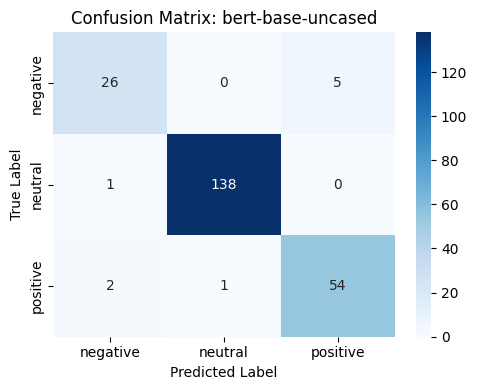

In [18]:
# Fine-tune bert-base-uncased as a general-domain baseline for comparison with the FinBERT domain-specific model.

# Fine-tuning bert-base-uncased (Devlin et al., 2019) via the HuggingFace Trainer (Wolf et al., 2020).

bert_model, bert_tokenizer, bert_trainer, bert_preds = train_and_evaluate(
    model_checkpoint='bert-base-uncased',
    output_dir=f'{BASE_DIR}/bert_output',
    label_names=LABEL_NAMES,
    texts_train=texts_train,
    texts_val=texts_val,
    texts_test=texts_test,
    labels_train=labels_train,
    labels_val=labels_val,
    labels_test=labels_test,
    class_weights=class_weights_array,
    max_length=MAX_LENGTH,
    seed=SEED
)

# Capture best checkpoint path before cleanup of trainer or model objects.
bert_best_ckpt = bert_trainer.state.best_model_checkpoint

bert_results = evaluate_model(
    'bert-base-uncased',
    labels_test,
    bert_preds,
    LABEL_NAMES
)

In [19]:
# Purpose: Save the fine-tuned bert-base-uncased model directly from memory.
# This ensures the correct weights are written to disk before the GPU cleanup cell runs.
# Saving from memory avoids issues that can appear when reloading from a checkpoint.

bert_save_dir = f'{BASE_DIR}/submission/bert_base_uncased'
os.makedirs(bert_save_dir, exist_ok=True)
bert_model.save_pretrained(bert_save_dir)
bert_tokenizer.save_pretrained(bert_save_dir)
print(f'Saved fine-tuned bert-base-uncased to {bert_save_dir}')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned bert-base-uncased to /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission/bert_base_uncased


## Memory Cleanup Between Transformer Models

GPU memory is released before loading FinBERT to prevent out-of-memory errors on Colab T4 (approximately 15.8 GB VRAM). The model and trainer objects are deleted, the CUDA cache is emptied, and Python garbage collection is triggered.

In [20]:
# Purpose: Release GPU and Python memory before loading FinBERT to avoid out-of-memory errors.

del bert_model
del bert_trainer
torch.cuda.empty_cache()
gc.collect()
print('GPU memory released. Ready to load FinBERT.')

GPU memory released. Ready to load FinBERT.


## Fine-tuning: yiyanghkust/finbert-tone

FinBERT (Yang et al., 2020) is fine-tuned as the domain-specific model. The finbert-tone checkpoint was pre-trained on financial communications text and had already been fine-tuned for sentiment on analyst-report sentences before this project. It is compared with bert-base-uncased under identical fine-tuning settings, and any difference in performance reflects both its financial pre-training and its prior sentiment training.

Cited: Yang et al. (2020)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: yiyanghkust/finbert-tone
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Starting training for yiyanghkust/finbert-tone


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
1,0.697636,0.341578,0.850577,0.856798,0.880933
2,0.264189,0.243135,0.929368,0.928394,0.931284
3,0.037419,0.297708,0.955165,0.955846,0.957541
4,0.031067,0.297929,0.946076,0.941993,0.950642
5,0.002149,0.284587,0.946076,0.941993,0.950642


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


Results: yiyanghkust/finbert-tone
  Macro F1:        0.9422
  Macro Precision: 0.9420
  Macro Recall:    0.9430
  Weighted F1:     0.9606

Per-class report:
              precision    recall  f1-score   support

    negative       0.93      0.90      0.92        31
     neutral       0.99      0.98      0.99       139
    positive       0.90      0.95      0.92        57

    accuracy                           0.96       227
   macro avg       0.94      0.94      0.94       227
weighted avg       0.96      0.96      0.96       227



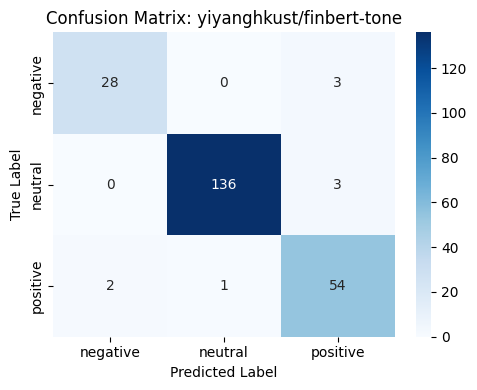

In [21]:
# Purpose: Fine-tune yiyanghkust/finbert-tone as the primary domain-specific model
# for comparison against the general-domain BERT baseline.

# Fine-tuning yiyanghkust/finbert-tone (Yang et al., 2020) via the HuggingFace Trainer (Wolf et al., 2020).

finbert_tone_model, finbert_tone_tokenizer, finbert_tone_trainer, finbert_tone_preds = train_and_evaluate(
    model_checkpoint='yiyanghkust/finbert-tone',
    output_dir=f'{BASE_DIR}/finberttone_output',
    label_names=LABEL_NAMES,
    texts_train=texts_train,
    texts_val=texts_val,
    texts_test=texts_test,
    labels_train=labels_train,
    labels_val=labels_val,
    labels_test=labels_test,
    class_weights=class_weights_array,
    max_length=MAX_LENGTH,
    seed=SEED
)

# Capture the best checkpoint path before any later cleanup so that the
# model can be reloaded from disk during dynamic saving without holding
# the trainer object in memory.
finbert_tone_best_ckpt = finbert_tone_trainer.state.best_model_checkpoint

finbert_tone_results = evaluate_model(
    'yiyanghkust/finbert-tone',
    labels_test,
    finbert_tone_preds,
    LABEL_NAMES
)

In [22]:
# Purpose: Save the fine-tuned yiyanghkust/finbert-tone model directly from memory.
# This ensures the correct weights are written to disk while the model is still loaded.
# Saving from memory avoids issues that can occur when reloading from a checkpoint.

finbert_save_dir = f'{BASE_DIR}/submission/finbert'
os.makedirs(finbert_save_dir, exist_ok=True)
finbert_tone_model.save_pretrained(finbert_save_dir)
finbert_tone_tokenizer.save_pretrained(finbert_save_dir)
print(f'Saved fine-tuned yiyanghkust/finbert-tone to {finbert_save_dir}')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned yiyanghkust/finbert-tone to /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission/finbert


## Results Summary Table

All four models are compared on macro-F1, macro precision, and macro recall.

In [23]:
# Purpose: Compile, display, and save a summary table comparing all models.
# Reports macro F1, macro precision, macro recall, and weighted F1.
# Weighted F1 is included to show the gap with macro F1
# and defend the choice of primary metric for class-imbalanced data.

results_summary = pd.DataFrame({
    'Model': [
        'Majority Class Baseline',
        'TF-IDF Logistic Regression',
        'bert-base-uncased',
        'yiyanghkust/finbert-tone'
    ],
    'Macro F1': [
        majority_results['f1'],
        tfidf_results['f1'],
        bert_results['f1'],
        finbert_tone_results['f1']
    ],
    'Macro Precision': [
        majority_results['precision'],
        tfidf_results['precision'],
        bert_results['precision'],
        finbert_tone_results['precision']
    ],
    'Macro Recall': [
        majority_results['recall'],
        tfidf_results['recall'],
        bert_results['recall'],
        finbert_tone_results['recall']
    ],
    'Weighted F1': [
        majority_results.get('f1_weighted', float('nan')),
        tfidf_results.get('f1_weighted',   float('nan')),
        bert_results.get('f1_weighted',    float('nan')),
        finbert_tone_results.get('f1_weighted', float('nan'))
    ],
}).round(4)

print(results_summary.to_string(index=False))

# Save as CSV for the report.
os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)
results_summary.to_csv(f'{BASE_DIR}/submission/results_summary.csv', index=False)
print(f'\nSaved results table to {BASE_DIR}/submission/results_summary.csv')

                     Model  Macro F1  Macro Precision  Macro Recall  Weighted F1
   Majority Class Baseline    0.2532           0.2041        0.3333       0.4651
TF-IDF Logistic Regression    0.7948           0.7978        0.7945       0.8386
         bert-base-uncased    0.9302           0.9349        0.9263       0.9601
  yiyanghkust/finbert-tone    0.9422           0.9420        0.9430       0.9606

Saved results table to /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission/results_summary.csv


## Misclassified Example Extraction and Cross-Model Error Analysis

Misclassified examples are extracted for manual error analysis. Cross-model overlap between FinBERT and bert-base-uncased separates errors shared by both models from errors made by only one model, supporting a qualitative comparison of where each model struggles. These patterns do not establish the causal effect of pre-training or prior sentiment training.

The sample is drawn with deliberate stratification across these partitions, allowing the report to compare error kinds rather than reporting a single undifferentiated set. A target sample size of 50 examples is used (within the 20 to 50 range required by the brief), split evenly between shared errors and FinBERT-only errors where availability permits, topped up with bert-base-uncased-only errors when one partition is smaller than its quota.

Rationale for extending the pool to the validation split: Because both transformer models are strong on this dataset, the unique test-set misclassification pool is small: 12 examples in total, comprising 6 shared errors, 3 FinBERT only errors, and 3 bert-base-uncased only errors. This falls below the minimum of 20 examples stipulated by the coursework brief for manual error analysis.

To reach the required floor without compromising the held-out status of the test set for headline metrics, the pool is extended to errors on the validation split. The validation split is drawn from the same stratified 80/10/10 partition with the same fixed random seed and is never used to compute reported test-set performance. This extension enlarges the qualitative sample without contaminating the quantitative evaluation. A 'split' column records the source (test or validation) of every sampled row so that the report can distinguish the two populations. This procedure yields a final compliant sample of 24 misclassified examples.

Each sampled example is exported with an empty error_category column for manual tagging. The categories used in the report are: forward-looking guidance, explicit or implicit negation, quantitative-only sentences with no sentiment-bearing lexical cues, contrastive clauses (for example, a positive headline followed by a negative qualifier), and neutral-positive boundary cases where the gold label reflects PhraseBank annotator consensus on subtle phrasing. This taxonomy is justified in the report and the resulting category distribution is reported for both partitions.

In [24]:
# Extract misclassified examples for manual error analysis.
# Primary pool: test-set errors, partitioned into shared, FinBERT-only, and bert-base-uncased-only.
#
# Rationale for the validation-set fallback implemented below:
# Both transformer models are strong on Financial PhraseBank, the test-set error pool is small.
# The unique test-set misclassification pool contains only 12 examples in total
# (6 shared, 3 FinBERT-only, 3 bert-base-uncased-only),
# which falls below the coursework brief minimum of 20 examples for manual error analysis.
# Restricting the analysis to the test split alone would therefore be non-compliant with the brief.
# To reach the 20-example floor without contaminating the headline metrics,
# the pool is extended with errors drawn from the validation split.
# The validation split comes from the same stratified 80/10/10 partition under the same fixed seed
# and is never used to compute reported test metrics.
# This extension enlarges the qualitative sample without affecting the quantitative evaluation.
# This procedure produces a final compliant sample of 24 misclassified examples.
# A 'split' column records the source (test or validation) of every row
# allowing the report to distinguish the two populations when discussing error patterns.

finbert_preds_arr = np.array(finbert_tone_preds)
bert_preds_arr = np.array(bert_preds)
labels_test_arr = np.array(labels_test)

# Test-set partitions.
finbert_wrong_mask = finbert_preds_arr != labels_test_arr
bert_wrong_mask = bert_preds_arr != labels_test_arr
overlap_mask = finbert_wrong_mask & bert_wrong_mask
finbert_only_mask = finbert_wrong_mask & (~bert_wrong_mask)
bert_only_mask = bert_wrong_mask & (~finbert_wrong_mask)

overlap_idx = np.where(overlap_mask)[0]
finbert_only_idx = np.where(finbert_only_mask)[0]
bert_only_idx = np.where(bert_only_mask)[0]

print('TEST SET')
print(f'  Total FinBERT misclassifications:           {finbert_wrong_mask.sum()}')
print(f'  Total bert-base-uncased misclassifications: {bert_wrong_mask.sum()}')
print(f'  Shared errors:                              {len(overlap_idx)}')
print(f'  FinBERT-only errors:                        {len(finbert_only_idx)}')
print(f'  bert-base-uncased-only errors:              {len(bert_only_idx)}')

TARGET_TOTAL = 50
MIN_REQUIRED = 20
TARGET_PER_BIN = TARGET_TOTAL // 2
rng = np.random.default_rng(seed=SEED)

def _sample(idx_array, k):
    k = min(k, len(idx_array))
    if k == 0:
        return np.array([], dtype=int)
    return rng.choice(idx_array, size=k, replace=False)

# Draw from test-set partitions first, balanced across shared and FinBERT-only bins,
# topped up with bert-base-uncased-only errors when available.
n_overlap = min(TARGET_PER_BIN, len(overlap_idx))
n_finonly = min(TARGET_PER_BIN, len(finbert_only_idx))

shortfall = TARGET_TOTAL - (n_overlap + n_finonly)
if shortfall > 0:
    extra_overlap = min(shortfall, len(overlap_idx) - n_overlap)
    n_overlap += extra_overlap
    shortfall -= extra_overlap
if shortfall > 0:
    extra_finonly = min(shortfall, len(finbert_only_idx) - n_finonly)
    n_finonly += extra_finonly
    shortfall -= extra_finonly

sample_overlap = _sample(overlap_idx, n_overlap)
sample_finonly = _sample(finbert_only_idx, n_finonly)
sample_bertonly = np.array([], dtype=int)
if shortfall > 0:
    sample_bertonly = _sample(bert_only_idx, min(shortfall, len(bert_only_idx)))

def _partition_test(idx):
    if overlap_mask[idx]:
        return 'shared'
    if finbert_only_mask[idx]:
        return 'finbert_only'
    return 'bert_only'

error_rows = []
for idx in np.concatenate([sample_overlap, sample_finonly, sample_bertonly]):
    error_rows.append({
        'split':          'test',
        'index':          int(idx),
        'sentence':       texts_test[idx],
        'gold_label':     LABEL_NAMES[labels_test_arr[idx]],
        'finbert_pred':   LABEL_NAMES[finbert_preds_arr[idx]],
        'bert_pred':      LABEL_NAMES[bert_preds_arr[idx]],
        'partition':      _partition_test(idx),
        'error_category': ''
    })

# If the test-set pool is below the brief floor, extend with validation-set errors.
# The validation set comes from the same stratified partition and is not used for
# headline metrics.
if len(error_rows) < MIN_REQUIRED:
    needed = TARGET_TOTAL - len(error_rows)
    print(f'\nTest-set pool ({len(error_rows)}) is below the brief floor of {MIN_REQUIRED}. '
          f'Extending with validation-set errors to reach up to {TARGET_TOTAL}.')

    val_finbert_dir = f'{BASE_DIR}/submission/finbert'
    val_bert_dir    = f'{BASE_DIR}/submission/bert_base_uncased'

    def _predict_dir(model_dir, texts, max_len):
        tok = AutoTokenizer.from_pretrained(model_dir)
        mdl = AutoModelForSequenceClassification.from_pretrained(model_dir).to(DEVICE)
        mdl.eval()
        out = []
        with torch.no_grad():
            for i in range(0, len(texts), 16):
                enc = tok(texts[i:i+16], padding='max_length', truncation=True,
                          max_length=max_len, return_tensors='pt').to(DEVICE)
                out.extend(torch.argmax(mdl(**enc).logits, dim=-1).cpu().numpy().tolist())
        del mdl
        torch.cuda.empty_cache()
        return np.array(out)

    finbert_val_preds = _predict_dir(val_finbert_dir, texts_val, MAX_LENGTH)
    bert_val_preds    = _predict_dir(val_bert_dir,    texts_val, MAX_LENGTH)
    labels_val_arr    = np.array(labels_val)

    finbert_val_wrong = finbert_val_preds != labels_val_arr
    bert_val_wrong    = bert_val_preds    != labels_val_arr
    val_overlap       = finbert_val_wrong & bert_val_wrong
    val_finonly       = finbert_val_wrong & (~bert_val_wrong)
    val_bertonly      = bert_val_wrong    & (~finbert_val_wrong)

    val_overlap_idx  = np.where(val_overlap)[0]
    val_finonly_idx  = np.where(val_finonly)[0]
    val_bertonly_idx = np.where(val_bertonly)[0]

    print('VALIDATION SET')
    print(f'  Shared errors:          {len(val_overlap_idx)}')
    print(f'  FinBERT-only errors:    {len(val_finonly_idx)}')
    print(f'  bert-only errors:       {len(val_bertonly_idx)}')

    # Proportional fill from validation partitions.
    val_pool = [
        (val_overlap_idx,  'shared'),
        (val_finonly_idx,  'finbert_only'),
        (val_bertonly_idx, 'bert_only'),
    ]
    per_bin = max(1, needed // 3)
    drawn = 0
    for idx_pool, partition in val_pool:
        if drawn >= needed:
            break
        take = min(per_bin, len(idx_pool), needed - drawn)
        chosen = _sample(idx_pool, take)
        for idx in chosen:
            error_rows.append({
                'split':          'validation',
                'index':          int(idx),
                'sentence':       texts_val[idx],
                'gold_label':     LABEL_NAMES[labels_val_arr[idx]],
                'finbert_pred':   LABEL_NAMES[finbert_val_preds[idx]],
                'bert_pred':      LABEL_NAMES[bert_val_preds[idx]],
                'partition':      partition,
                'error_category': ''
            })
            drawn += 1

    # Sweep any residual capacity across partitions in order of size.
    if drawn < needed:
        remaining = [(idx_pool, partition) for idx_pool, partition in val_pool]
        remaining.sort(key=lambda p: -len(p[0]))
        for idx_pool, partition in remaining:
            if drawn >= needed:
                break
            already = {r['index'] for r in error_rows if r['split'] == 'validation' and r['partition'] == partition}
            available = np.array([i for i in idx_pool if i not in already], dtype=int)
            take = min(needed - drawn, len(available))
            if take == 0:
                continue
            chosen = _sample(available, take)
            for idx in chosen:
                error_rows.append({
                    'split':          'validation',
                    'index':          int(idx),
                    'sentence':       texts_val[idx],
                    'gold_label':     LABEL_NAMES[labels_val_arr[idx]],
                    'finbert_pred':   LABEL_NAMES[finbert_val_preds[idx]],
                    'bert_pred':      LABEL_NAMES[bert_val_preds[idx]],
                    'partition':      partition,
                    'error_category': ''
                })
                drawn += 1

errors_df = pd.DataFrame(error_rows)
os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)
out_path = f'{BASE_DIR}/submission/misclassified_examples.csv'
errors_df.to_csv(out_path, index=False)

print(f'\nSampled {len(errors_df)} misclassified examples in total.')
print(f'  By split:     {errors_df["split"].value_counts().to_dict()}')
print(f'  By partition: {errors_df["partition"].value_counts().to_dict()}')
print(f'Saved to {out_path}')
print(errors_df[['split', 'partition', 'gold_label', 'finbert_pred', 'bert_pred']].head(10))

if len(errors_df) < MIN_REQUIRED:
    print(f'\nWARNING: only {len(errors_df)} misclassified examples available '
          f'across both models and both splits; brief floor of {MIN_REQUIRED} not met. '
          f'This limitation must be reported in the error analysis section.')

TEST SET
  Total FinBERT misclassifications:           9
  Total bert-base-uncased misclassifications: 9
  Shared errors:                              6
  FinBERT-only errors:                        3
  bert-base-uncased-only errors:              3

Test-set pool (12) is below the brief floor of 20. Extending with validation-set errors to reach up to 50.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

VALIDATION SET
  Shared errors:          3
  FinBERT-only errors:    6
  bert-only errors:       3

Sampled 24 misclassified examples in total.
  By split:     {'test': 12, 'validation': 12}
  By partition: {'shared': 9, 'finbert_only': 9, 'bert_only': 6}
Saved to /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission/misclassified_examples.csv
  split     partition gold_label finbert_pred bert_pred
0  test        shared   positive     negative  negative
1  test        shared   negative     positive  positive
2  test        shared   positive      neutral   neutral
3  test        shared   negative     positive  positive
4  test        shared   positive     negative  negative
5  test        shared    neutral     positive  negative
6  test  finbert_only   negative     positive  negative
7  test  finbert_only    neutral     positive   neutral
8  test  finbert_only    neutral     positive   neutral
9  test     bert_only   negative     negative  positive


## Dynamic Model Saving

The Majority Class baseline has no serialisable model object and is excluded
from this comparison. The three remaining candidates (TF-IDF with Logistic
Regression, bert-base-uncased, FinBERT) are ranked by test macro-F1 and the
top two are saved to disk.

In [25]:
# Purpose: Rank the three trainable models by test macro-F1, save the top two,
# and remove any artefact that did not make the cut.
# The final submission contains exactly the two best-performing models as required by the marking scheme.
# After saving the TF-IDF pipeline, a load-back verification step is run
# to catch any pickling problems.

import shutil

os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)

# Persist eval-time configuration, ensuring the marker cell
# uses the exact same MAX_LENGTH as used in training.

import json
with open(f'{BASE_DIR}/submission/eval_config.json', 'w') as _f:
    json.dump({'max_length': int(MAX_LENGTH)}, _f)

# Majority Class is excluded because DummyClassifier produces no meaningful artefact.
candidate_models = {
    'tfidf_lr':          tfidf_results['f1'],
    'bert_base_uncased': bert_results['f1'],
    'finbert':           finbert_tone_results['f1'],
}

# Sort by F1 descending, breaking ties by model name.
ranked = sorted(candidate_models.items(), key=lambda x: (-x[1], x[0]))
top_two = [name for name, _ in ranked[:2]]

print('Model ranking by test macro-F1:')
for name, score in ranked:
    tag = 'KEPT' if name in top_two else 'REMOVED'
    print(f'  {name:25s}: {score:.4f}  {tag}')

# TF-IDF + LR pipeline.
tfidf_path = f'{BASE_DIR}/submission/tfidf_lr_pipeline.joblib'
if 'tfidf_lr' in top_two:
    joblib.dump(tfidf_pipeline, tfidf_path)
    # Load-back verification: ensures the pickled FunctionTransformer resolves correctly.
    _verify = joblib.load(tfidf_path)
    _ = _verify.predict(texts_test[:2])
    del _verify
    print('Kept and verified: tfidf_lr_pipeline.joblib')
elif os.path.isfile(tfidf_path):
    os.remove(tfidf_path)
    print('Removed: tfidf_lr_pipeline.joblib')

# bert-base-uncased directory.
bert_dir = f'{BASE_DIR}/submission/bert_base_uncased'
if 'bert_base_uncased' not in top_two and os.path.isdir(bert_dir):
    shutil.rmtree(bert_dir)
    print('Removed: bert_base_uncased/')
elif 'bert_base_uncased' in top_two:
    print('Kept: bert_base_uncased/')

# finbert directory.
finbert_dir = f'{BASE_DIR}/submission/finbert'
if 'finbert' not in top_two and os.path.isdir(finbert_dir):
    shutil.rmtree(finbert_dir)
    print('Removed: finbert/')
elif 'finbert' in top_two:
    print('Kept: finbert/')

Model ranking by test macro-F1:
  finbert                  : 0.9422  KEPT
  bert_base_uncased        : 0.9302  KEPT
  tfidf_lr                 : 0.7948  REMOVED
Kept: bert_base_uncased/
Kept: finbert/


## Test Set Export

In [26]:
# Purpose: Export the test split to CSV
# to enable reproduction of evaluation on the exact held-out partition used.

test_df = pd.DataFrame({'sentence': texts_test, 'label': labels_test})
os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)
test_df.to_csv(f'{BASE_DIR}/submission/test_set.csv', index=False)
print(f'Saved test_set.csv with {len(test_df)} rows.')

Saved test_set.csv with 227 rows.


## README Generation

Software versions are captured at runtime so the readme always reflects
the actual Colab environment rather than hardcoded strings that may become stale.

In [31]:
# Generate readme.txt with instructions for the marker
# and a manifest of package contents and runtime environment.

import os
import sys
import torch
import transformers
import pandas as pd
import numpy as np
import joblib
import nltk
import sklearn
import datasets as hf_datasets

readme_content = f"""INM434 NLP Final Coursework
Author: Mario Andres Melo Ceron
Student ID: [redacted]
Google Colab Notebook Link:
[link removed]

City SharePoint Models Link:
[link removed]


MOODLE SUBMISSION ITEMS
Per the coursework brief, four items are uploaded to Moodle:
    Item 1: submission.zip (this archive).
    Item 2: INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt
            (concatenated code as a single text file, uploaded as a
            standalone file). A copy of the same file is also included
            inside this zip for reviewer convenience.
    Item 3: the PDF report.
    Item 4: the supplementary PDF (up to 4 A4 pages).

MODEL DOWNLOAD (REQUIRED BEFORE RUNNING THE MARKER CELL)
The two fine-tuned model folders (bert_base_uncased/ and finbert/) are hosted on City SharePoint
because their combined size of approximately 780 MB exceeds the Moodle upload limit.
The remaining files are already bundled in submission.zip.

City SharePoint link:

    [link removed]

The City SharePoint link above opens a folder named 'INM434_NLP_Models_Mario_Melo' which contains
both model subfolders (bert_base_uncased/ and finbert/). After unzipping submission.zip, download
both subfolders from that SharePoint location and place them directly inside the unzipped submission.

The final layout is:

    submission/
      bert_base_uncased/     (downloaded from City SharePoint)
      finbert/               (downloaded from City SharePoint)
      INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.ipynb
      test_set.csv
      readme.txt
      (and the remaining bundled files)

INSTRUCTIONS FOR THE MARKER
This submission package contains the live notebook and the held-out test set.
The two best-trained model folders are hosted separately on City SharePoint (see MODEL DOWNLOAD section above)
because they exceed the Moodle upload limit.
Model retraining is not required. Only one cell needs to be executed for evaluation.

The marker evaluation cell is FULLY SELF-CONTAINED: it re-imports every library it needs,
does not depend on any earlier cell in the notebook having been executed, does not mount Google Drive.

How to run the marker evaluation cell:
1. Unzip submission.zip into any working directory.
2. Download the two model folders from the City SharePoint link in the MODEL DOWNLOAD section above
   and place them inside the unzipped submission directory.
3. Open INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.ipynb in Google Colab.
4. If the working directory differs from the default, set the submission path before running the marker cell:
       import os
       os.environ['INM434_SUBMISSION_DIR'] = '/path/to/unzipped/submission'

5. Scroll to the final cell, titled 'MARKER CELL: Evaluate the two best-trained models on the held-out test set',
   and run that cell.
6. The cell is self-contained within a standard Google Colab runtime:
   it imports every library it needs from the default Colab environment,
   does not mount Google Drive, downloads only the NLTK resources it requires, locates the submission folder,
   restores the two saved models and the bundled test set, runs inference,
   and prints macro F1, precision, recall, classification reports, and confusion matrices for each model.
7. A runtime restart is not required.
If running outside Google Colab, ensure the packages listed under DEPENDENCIES are installed at compatible versions first.

Expected runtime on Google Colab with T4 GPU: under 60 seconds.

MODELS EVALUATED IN THIS COURSEWORK
The notebook fine-tunes and compares four models on the Financial PhraseBank sentences_allagree configuration:
 1. Majority Class baseline (sklearn DummyClassifier)
 2. TF-IDF with Logistic Regression (sklearn Pipeline)
 3. bert-base-uncased (general-domain transformer, Devlin et al. 2019)
 4. yiyanghkust/finbert-tone (domain-specific transformer, Yang et al. 2020)

The two best-performing models are selected dynamically by ranking test macro-F1 across the three trainable candidates
(TF-IDF Logistic Regression, bert-base-uncased, yiyanghkust/finbert-tone).
The Majority Class baseline is excluded, as it does not produce a serialisable model artefact.

PACKAGE CONTENTS
submission.zip contains:
    INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.ipynb  (notebook, runnable)
    INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt    (copy of the concatenated code file; Moodle item 2 is the same file uploaded standalone)
    readme.txt                                                         (this file)
    test_set.csv                                                       (held-out test partition)
    misclassified_examples.csv                                         (error analysis sample)
    results_summary.csv                                                (all-model metrics table)
    bert_base_uncased/                                                 (not bundled in zip, download from the City SharePoint link in MODEL DOWNLOAD section above)
    finbert/                                                           (not bundled in zip, download from the City SharePoint link in MODEL DOWNLOAD section above)
    cm_majority_class_baseline.png                                     (confusion matrix)
    cm_tf-idf_logistic_regression.png                                  (confusion matrix)
    cm_bert-base-uncased.png                                           (confusion matrix)
    cm_yiyanghkust_finbert-tone.png                                    (confusion matrix)
    class_distribution.png                                             (EDA figure)
    token_length_distribution.png                                      (EDA figure)
    eval_config.json                                                   (tokenisation config: max_length)

Note: the folder named 'finbert/' inside the submission contains the yiyanghkust/finbert-tone weights.
The folder name is kept short for filesystem clarity; the full checkpoint identifier is recorded above.

DEPENDENCIES (runtime captured)
Python:       {sys.version}
PyTorch:      {torch.__version__}
Transformers: {transformers.__version__}
Datasets:     {hf_datasets.__version__}
Scikit-learn: {sklearn.__version__}
NLTK:         {nltk.__version__}
Joblib:       {joblib.__version__}
NumPy:        {np.__version__}
Pandas:       {pd.__version__}

NOTES
- The included test set is the exact held-out partition (stratified 80/10/10 split, seed=42).
- Raw text is provided to transformer tokenisers; preprocessing is only used for TF-IDF inputs.
- All random seeds are fixed at SEED=42 across Python, NumPy, PyTorch, CUDA, and HuggingFace.
- No HuggingFace Hub access is required to run marker evaluation.
- The provided Colab link is for reference; the evaluation cell works offline
  once the two model folders from the City SharePoint link have been placed inside the unzipped submission directory.
"""

os.makedirs(f'{BASE_DIR}/submission', exist_ok=True)
with open(f'{BASE_DIR}/submission/readme.txt', 'w') as f:
    f.write(readme_content)
print('readme.txt generated.')
print(readme_content)

readme.txt generated.
INM434 NLP Final Coursework
Author: Mario Andres Melo Ceron
Student ID: [redacted]
Google Colab Notebook Link: 
[link removed]

City SharePoint Models Link: 
[link removed]


MOODLE SUBMISSION ITEMS
Per the coursework brief, four items are uploaded to Moodle:
    Item 1: submission.zip (this archive).
    Item 2: INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt
            (concatenated code as a single text file, uploaded as a
            standalone file). A copy of the same file is also included
            inside this zip for reviewer convenience.
    Item 3: the PDF report.
    Item 4: the supplementary PDF (up to 4 A4 pages).

MODEL DOWNLOAD (REQUIRED BEFORE RUNNING THE MARKER CELL)
The two fine-tuned model folders (bert_base_uncased/ and finbert/) are hosted on City SharePoint
because their combined size of approximately 780 MB exceeds the Moodle upload limit.
The remaining files are already bundled in submission.zip.

City SharePoint link:

 

## Notebook Export and Zip Packaging

The notebook is also exported as a Python script. If programmatic conversion fails because the notebook path cannot be detected from inside Colab, a manual fallback instruction is printed. All artefacts are saved in the submission directory before zipping.

In [32]:
# Assemble the final submission deliverables.
# Produces the .zip package (all code, readme) and a single .txt file with all code concatenated.
# If nbconvert is unavailable, a pure-Python fallback guarantees the .txt file is always produced, as required.

import shutil
import json

CANONICAL_NB_NAME  = 'INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.ipynb'
CANONICAL_TXT_NAME = 'INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt'

live_notebook_candidates = [
    f'/content/drive/MyDrive/Colab Notebooks/{CANONICAL_NB_NAME}',
    f'/content/drive/MyDrive/{CANONICAL_NB_NAME}',
    f'/content/{CANONICAL_NB_NAME}',
    f'./{CANONICAL_NB_NAME}',
]
dest_nb = f'{BASE_DIR}/submission/{CANONICAL_NB_NAME}'
notebook_copied = False
for nb_path in live_notebook_candidates:
    if os.path.isfile(nb_path):
        shutil.copy(nb_path, dest_nb)
        print(f'Copied notebook from: {nb_path}')
        notebook_copied = True
        break
if not notebook_copied:
    print('WARNING: Live notebook not found at expected paths.')
    print('Manual step required: Download the notebook via File > Download > Download .ipynb')
    print(f'and place it in {BASE_DIR}/submission/ as {CANONICAL_NB_NAME}')

txt_in_zip      = f'{BASE_DIR}/submission/{CANONICAL_TXT_NAME}'
txt_standalone  = f'{BASE_DIR}/{CANONICAL_TXT_NAME}'

# Primary path: nbconvert.
nbconvert_ok = False
if notebook_copied:
    rc = os.system(
        f'jupyter nbconvert --to script "{dest_nb}" '
        f'--output-dir "{BASE_DIR}/submission/" 2>/dev/null'
    )
    py_path = f'{BASE_DIR}/submission/INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.py'
    if rc == 0 and os.path.isfile(py_path):
        if os.path.isfile(txt_in_zip):
            os.remove(txt_in_zip)
        os.rename(py_path, txt_in_zip)
        nbconvert_ok = True
        print('Concatenated code exported via nbconvert.')

# Pure-Python fallback: extract and concatenate code cells directly from .ipynb JSON.
if not nbconvert_ok and notebook_copied:
    with open(dest_nb) as f:
        nb_json = json.load(f)
    lines = []
    lines.append('# INM434 NLP Final Coursework')
    lines.append('# Author: Mario Andres Melo Ceron')
    lines.append('# Student ID: [redacted]')
    lines.append('# Concatenated code export (fallback path, pure Python)')
    lines.append('')
    for i, cell in enumerate(nb_json.get('cells', [])):
        if cell.get('cell_type') == 'code':
            src = cell.get('source', [])
            src = ''.join(src) if isinstance(src, list) else src
            lines.append(f'# Cell {i}')
            lines.append(src.rstrip())
            lines.append('')
    with open(txt_in_zip, 'w') as f:
        f.write('\n'.join(lines))
    print('Concatenated code exported via pure-Python fallback.')

if os.path.isfile(txt_in_zip):
    shutil.copy(txt_in_zip, txt_standalone)
    print(f'Concatenated code paths:')
    print(f'  (inside zip)   {txt_in_zip}')
    print(f'  (standalone)   {txt_standalone}')
else:
    print('ERROR: Concatenated .txt file could not be produced. '
          'Download the notebook manually and export it as .py via '
          'File > Download > Download .py, then rename to .txt.')

# Create the final zip archive
zip_path = f'{BASE_DIR}/submission.zip'
if os.path.isfile(zip_path):
    os.remove(zip_path)
!cd "{BASE_DIR}" && zip -r submission.zip submission/ > /dev/null

print('\nsubmission.zip created with clean relative paths.')
print(f'Contents of {BASE_DIR}/submission/:')
for f in sorted(os.listdir(f'{BASE_DIR}/submission')):
    print(f'  {f}')
print(f'\nFiles at {BASE_DIR}/ root for Moodle upload:')
for f in sorted(os.listdir(BASE_DIR)):
    if f in ('submission.zip', CANONICAL_TXT_NAME):
        print(f'  {f}')

Copied notebook from: /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.ipynb
Concatenated code exported via pure-Python fallback.
Concatenated code paths:
  (inside zip)   /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission/INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt
  (standalone)   /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt

submission.zip created with clean relative paths.
Contents of /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission/:
  INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.ipynb
  INM434_NLP_Financial_Sentiment_Analysis_Notebook_Mario_Melo.txt
  bert_base_uncased
  class_distribution.png
  cm_bert-base-uncased.png
  cm_majority_class_baseline.png
  cm_tf-idf_logistic_regression.png
  cm_yiyanghkust_finbert-tone.png
  eval_config.json
  finbert
  misclassified_examples.csv
  rea

## Runtime Version Summary

Software versions are printed at the end of the notebook to cross-reference against readme.txt and support reproducibility checks.

In [29]:
import sklearn
import datasets as hf_datasets

print('Runtime versions:')
print(f'  Python:       {sys.version}')
print(f'  PyTorch:      {torch.__version__}')
print(f'  Transformers: {transformers.__version__}')
print(f'  Datasets:     {hf_datasets.__version__}')
print(f'  Scikit-learn: {sklearn.__version__}')
print(f'  NLTK:         {nltk.__version__}')
print(f'  Joblib:       {joblib.__version__}')
print(f'  NumPy:        {np.__version__}')
print(f'  Pandas:       {pd.__version__}')

Runtime versions:
  Python:       3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
  PyTorch:      2.10.0+cu128
  Transformers: 5.0.0
  Datasets:     3.6.0
  Scikit-learn: 1.6.1
  NLTK:         3.9.1
  Joblib:       1.5.3
  NumPy:        2.0.2
  Pandas:       2.2.2


## MARKER CELL: Evaluate the two best-trained models on the held-out test set

This is the only cell required for evaluation. It loads the two best-trained models from the submission folder, restores the held-out test set, runs inference, and reports macro F1, macro precision, macro recall, the per-class classification report, and the confusion matrix for each of the two best-trained models. No model retraining is performed.

**Important:** the two model folders (`bert_base_uncased/` and `finbert/`) are not bundled inside submission.zip because their combined size exceeds the Moodle upload limit. They must be downloaded separately from the City SharePoint link below and placed inside the unzipped submission directory before running this cell.

**City SharePoint Models Link:** [link removed]

For detailed instructions on running this cell, the structure of the submission package, required library dependencies, and expected runtime, please refer to the `readme.txt` file included in the submission archive.

Loading submission package from: /content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission

Using MAX_LENGTH=64 for transformer tokenisation

Loaded test set: 227 sentences

Inference device: cuda

Evaluating: bert-base-uncased


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Results for bert-base-uncased
  Macro F1:        0.9302
  Macro Precision: 0.9349
  Macro Recall:    0.9263
  Weighted F1:     0.9601

Per-class classification report:
              precision    recall  f1-score   support

    negative       0.90      0.84      0.87        31
     neutral       0.99      0.99      0.99       139
    positive       0.92      0.95      0.93        57

    accuracy                           0.96       227
   macro avg       0.93      0.93      0.93       227
weighted avg       0.96      0.96      0.96       227



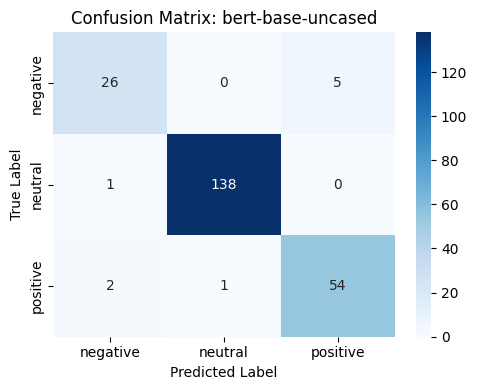

Evaluating: yiyanghkust/finbert-tone


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Results for yiyanghkust/finbert-tone
  Macro F1:        0.9422
  Macro Precision: 0.9420
  Macro Recall:    0.9430
  Weighted F1:     0.9606

Per-class classification report:
              precision    recall  f1-score   support

    negative       0.93      0.90      0.92        31
     neutral       0.99      0.98      0.99       139
    positive       0.90      0.95      0.92        57

    accuracy                           0.96       227
   macro avg       0.94      0.94      0.94       227
weighted avg       0.96      0.96      0.96       227



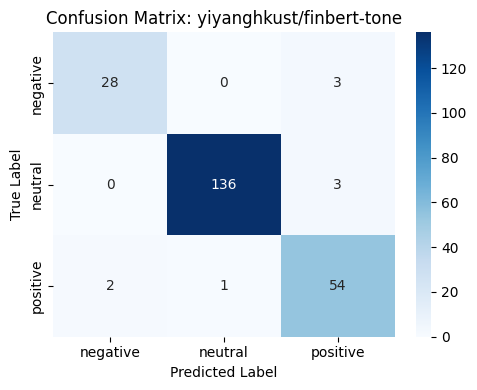


Marker evaluation complete. 2 model(s) evaluated.


In [30]:
# Self-contained marker evaluation cell.
# Loads the two best-trained models (downloaded separately from the City SharePoint
# link provided in the markdown cell above and in readme.txt, then placed inside
# the unzipped submission directory) together with the bundled test set, runs
# inference, and prints all evaluation metrics.

import os
import sys
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)
from transformers import AutoTokenizer, AutoModelForSequenceClassification

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

for _resource in ['stopwords', 'wordnet', 'omw-1.4']:
    try:
        nltk.data.find(f'corpora/{_resource}')
    except LookupError:
        nltk.download(_resource, quiet=True)

_STOP_WORDS = set(stopwords.words('english'))
_NEGATION_CUES = {'not', 'no', 'never', 'neither', 'nor', 'nobody', 'nothing',
                  'nowhere', 'hardly', 'scarcely', 'barely', "n't"}
_STOP_WORDS -= _NEGATION_CUES
_lemmatizer = WordNetLemmatizer()

# This function is kept identical to training-time preprocess_text.
# Used only if called manually for inspection; TF-IDF pipeline pickles its own.
def preprocess_text(text):
    # Step 1: Regex cleaning
    text = re.sub(r"n't\b", " not", text, flags=re.IGNORECASE)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    # Step 2: Lowercase
    text = text.lower()
    # Step 3: Negation handling
    tokens = text.split()
    negated_tokens = []
    negate_next = False
    for token in tokens:
        if token in _NEGATION_CUES:
            negate_next = True
            continue
        if negate_next:
            negated_tokens.append('NOT_' + token)
            negate_next = False
        else:
            negated_tokens.append(token)
    tokens = negated_tokens
    # Step 4: Stopword removal
    tokens = [t for t in tokens if t not in _STOP_WORDS]
    # Step 5: Lemmatisation
    tokens = [_lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

def _preprocess_batch(texts):
    return [preprocess_text(t) for t in texts]

candidate_paths = [
    os.environ.get('INM434_SUBMISSION_DIR', ''),
    '/content/drive/MyDrive/Colab Notebooks/INM434_NLP_Outputs/submission',
    '/content/submission',
    './submission',
    'submission'
]

SUBMISSION_DIR = None
for path in candidate_paths:
    if path and os.path.isdir(path):
        SUBMISSION_DIR = path
        break

if SUBMISSION_DIR is None:
    raise FileNotFoundError(
        'Could not locate the submission directory. Set the environment '
        'variable INM434_SUBMISSION_DIR to the path of the unzipped '
        'submission folder before running this cell. The two model folders '
        '(bert_base_uncased/ and finbert/) must also be present inside that '
        'directory, downloaded from the City SharePoint link in readme.txt.'
    )

print(f'Loading submission package from: {SUBMISSION_DIR}\n')

import json
_cfg_path = os.path.join(SUBMISSION_DIR, 'eval_config.json')
if os.path.isfile(_cfg_path):
    with open(_cfg_path) as _f:
        EVAL_MAX_LENGTH = int(json.load(_f)['max_length'])
else:
    EVAL_MAX_LENGTH = 64
print(f'Using MAX_LENGTH={EVAL_MAX_LENGTH} for transformer tokenisation\n')

test_path = os.path.join(SUBMISSION_DIR, 'test_set.csv')
test_df = pd.read_csv(test_path)
texts_test_marker  = test_df['sentence'].astype(str).tolist()
labels_test_marker = test_df['label'].astype(int).tolist()
print(f'Loaded test set: {len(test_df)} sentences\n')

LABEL_NAMES_MARKER = ['negative', 'neutral', 'positive']

DEVICE_MARKER = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Inference device: {DEVICE_MARKER}\n')

def evaluate_marker(model_name, y_true, y_pred, label_names):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    _, _, f1_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )
    print(f'\nResults for {model_name}')
    print(f'  Macro F1:        {f1:.4f}')
    print(f'  Macro Precision: {precision:.4f}')
    print(f'  Macro Recall:    {recall:.4f}')
    print(f'  Weighted F1:     {f1_w:.4f}')
    print('\nPer-class classification report:')
    print(classification_report(y_true, y_pred,
                                target_names=label_names,
                                zero_division=0))
    cm = confusion_matrix(y_true, y_pred,
                          labels=list(range(len(label_names))))
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_names,
                yticklabels=label_names,
                ax=ax)
    ax.set_title(f'Confusion Matrix: {model_name}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()
    plt.show()

def predict_with_transformer(model_dir, texts):
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(DEVICE_MARKER)
    model.eval()
    preds_all = []
    batch_size = 16
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            enc = tokenizer(batch, padding='max_length', truncation=True,
                            max_length=EVAL_MAX_LENGTH, return_tensors='pt').to(DEVICE_MARKER)
            logits = model(**enc).logits
            preds_all.extend(torch.argmax(logits, dim=-1).cpu().numpy().tolist())
    return preds_all

bert_dir    = os.path.join(SUBMISSION_DIR, 'bert_base_uncased')
finbert_dir = os.path.join(SUBMISSION_DIR, 'finbert')
tfidf_path  = os.path.join(SUBMISSION_DIR, 'tfidf_lr_pipeline.joblib')

models_evaluated = 0

try:
    if os.path.isdir(bert_dir):
        print('=' * 60)
        print('Evaluating: bert-base-uncased')
        print('=' * 60)
        bert_preds_marker = predict_with_transformer(bert_dir, texts_test_marker)
        evaluate_marker('bert-base-uncased', labels_test_marker,
                        bert_preds_marker, LABEL_NAMES_MARKER)
        models_evaluated += 1
except Exception as e:
    print(f'FAILED to evaluate bert-base-uncased: {e}')

try:
    if os.path.isdir(finbert_dir):
        print('=' * 60)
        print('Evaluating: yiyanghkust/finbert-tone')
        print('=' * 60)
        finbert_preds_marker = predict_with_transformer(finbert_dir, texts_test_marker)
        evaluate_marker('yiyanghkust/finbert-tone', labels_test_marker,
                        finbert_preds_marker, LABEL_NAMES_MARKER)
        models_evaluated += 1
except Exception as e:
    print(f'FAILED to evaluate yiyanghkust/finbert-tone: {e}')

try:
    if os.path.isfile(tfidf_path):
        print('=' * 60)
        print('Evaluating: TF-IDF with Logistic Regression')
        print('=' * 60)
        tfidf_pipeline_marker = joblib.load(tfidf_path)
        tfidf_preds_marker = tfidf_pipeline_marker.predict(texts_test_marker)
        evaluate_marker('TF-IDF Logistic Regression', labels_test_marker,
                        tfidf_preds_marker, LABEL_NAMES_MARKER)
        models_evaluated += 1
except Exception as e:
    print(f'FAILED to evaluate TF-IDF Logistic Regression: {e}')

print(f'\n{"=" * 60}')
print(f'Marker evaluation complete. {models_evaluated} model(s) evaluated.')
print('=' * 60)